# Modelo Baseline y registro de experimento con MLflow

## 1. Carga y descripción del dataset

Para esta actividad se utiliza el dataset **Store Sales - Time Series Forecasting**, que contiene información histórica de ventas de distintas tiendas y familias de productos.

El objetivo principal será utilizar las variables disponibles para construir posteriormente un modelo baseline capaz de estimar la variable `sales`.

Para enriquecer el análisis se utilizan tres archivos:

- `train.csv`: contiene las ventas históricas por fecha, tienda y familia de productos.
- `stores.csv`: contiene información adicional sobre cada tienda, como ciudad, estado, tipo y cluster.
- `oil.csv`: contiene el precio diario del petróleo.

Los datasets se combinan utilizando `store_nbr` y `date` como claves, generando un único DataFrame para el análisis.

In [2]:
import pandas as pd

# Carga de los datasets principales
train = pd.read_csv("train.csv")
stores = pd.read_csv("stores.csv")
oil = pd.read_csv("oil.csv")

# Conversión de la fecha a tipo datetime
train["date"] = pd.to_datetime(train["date"])
oil["date"] = pd.to_datetime(oil["date"])

# Unión de la información de las tiendas
df = train.merge(
  stores,
  on="store_nbr",
  how="left"
)

# Unión con la información del precio del petróleo
df = df.merge(
  oil,
  on="date",
  how="left"
)

print("Datasets cargados y combinados correctamente.")

Datasets cargados y combinados correctamente.


In [3]:
print("Dimensiones de train:", train.shape)
print("Dimensiones de stores:", stores.shape)
print("Dimensiones de oil:", oil.shape)
print("Dimensiones del dataset combinado:", df.shape)

Dimensiones de train: (3000888, 6)
Dimensiones de stores: (54, 5)
Dimensiones de oil: (1218, 2)
Dimensiones del dataset combinado: (3000888, 11)


In [4]:
df.head()

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,NaN
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,NaN
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,NaN
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,NaN
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 11 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
 6   city         str           
 7   state        str           
 8   type         str           
 9   cluster      int64         
 10  dcoilwtico   float64       
dtypes: datetime64[us](1), float64(2), int64(4), str(4)
memory usage: 331.7 MB


In [7]:
print("Variables del dataset:")

for column in df.columns:
  print("-", column)

Variables del dataset:
- id
- date
- store_nbr
- family
- sales
- onpromotion
- city
- state
- type
- cluster
- dcoilwtico


In [8]:
df.dtypes

id                      int64
date           datetime64[us]
store_nbr               int64
family                    str
sales                 float64
onpromotion             int64
city                      str
state                     str
type                      str
cluster                 int64
dcoilwtico            float64
dtype: object

In [9]:
df.describe()

,id,date,store_nbr,sales,onpromotion,cluster,dcoilwtico
count,3.000888e+06,3000888,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06,2.072466e+06
mean,1.500444e+06,2015-04-24 08:27:04.703088,2.750000e+01,3.577757e+02,2.602770e+00,8.481481e+00,6.792559e+01
min,0.000000e+00,2013-01-01 00:00:00,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.619000e+01
25%,7.502218e+05,2014-02-26 18:00:00,1.400000e+01,0.000000e+00,0.000000e+00,4.000000e+00,4.638000e+01
50%,1.500444e+06,2015-04-24 12:00:00,2.750000e+01,1.100000e+01,0.000000e+00,8.500000e+00,5.333000e+01
75%,2.250665e+06,2016-06-19 06:00:00,4.100000e+01,1.958473e+02,0.000000e+00,1.300000e+01,9.580000e+01
max,3.000887e+06,2017-08-15 00:00:00,5.400000e+01,1.247170e+05,7.410000e+02,1.700000e+01,1.106200e+02
std,8.662819e+05,NaN,1.558579e+01,1.101998e+03,1.221888e+01,4.649735e+00,2.566633e+01


### Descripción de las variables

| Variable | Descripción |
|---|---|
| `id` | Identificador único del registro. |
| `date` | Fecha en la que se registraron las ventas. |
| `store_nbr` | Identificador de la tienda. |
| `family` | Familia o categoría del producto. |
| `sales` | Cantidad de ventas registradas. Es la variable objetivo del modelo. |
| `onpromotion` | Número de productos de esa familia que se encontraban en promoción. |
| `city` | Ciudad donde se encuentra la tienda. |
| `state` | Estado o provincia donde se encuentra la tienda. |
| `type` | Tipo de tienda. |
| `cluster` | Grupo de tiendas con características similares. |
| `dcoilwtico` | Precio diario del petróleo. |

In [12]:
df.shape

(3000888, 11)

### Descripción de la estructura del dataset

Después de combinar los archivos `train.csv`, `stores.csv` y `oil.csv`, el conjunto de datos resultante contiene **3,000,888 registros y 11 variables**.

Las variables presentan distintos tipos de datos. `date` fue convertida a un tipo de fecha (`datetime`), mientras que variables como `id`, `store_nbr`, `onpromotion` y `cluster` son numéricas enteras. Las variables `sales` y `dcoilwtico` son numéricas continuas, y `family`, `city`, `state` y `type` son variables categóricas.

La variable **`sales` será la variable objetivo** del modelo, ya que representa las ventas registradas para una determinada familia de productos, tienda y fecha.

También se observa desde los primeros registros que la variable `dcoilwtico`, correspondiente al precio del petróleo, contiene algunos valores faltantes. Estos valores serán analizados posteriormente durante la etapa de limpieza de datos antes de decidir cómo tratarlos.

In [13]:
print("Fecha inicial:", df["date"].min())
print("Fecha final:", df["date"].max())

print("\nNúmero de tiendas:", df["store_nbr"].nunique())
print("Número de familias de productos:", df["family"].nunique())
print("Número de ciudades:", df["city"].nunique())
print("Número de estados:", df["state"].nunique())
print("Número de tipos de tienda:", df["type"].nunique())
print("Número de clusters:", df["cluster"].nunique())

Fecha inicial: 2013-01-01 00:00:00
Fecha final: 2017-08-15 00:00:00

Número de tiendas: 54
Número de familias de productos: 33
Número de ciudades: 22
Número de estados: 16
Número de tipos de tienda: 5
Número de clusters: 17


In [14]:
df[["sales", "onpromotion", "dcoilwtico"]].describe()

,sales,onpromotion,dcoilwtico
count,3.000888e+06,3.000888e+06,2.072466e+06
mean,3.577757e+02,2.602770e+00,6.792559e+01
std,1.101998e+03,1.221888e+01,2.566633e+01
min,0.000000e+00,0.000000e+00,2.619000e+01
25%,0.000000e+00,0.000000e+00,4.638000e+01
50%,1.100000e+01,0.000000e+00,5.333000e+01
75%,1.958473e+02,0.000000e+00,9.580000e+01
max,1.247170e+05,7.410000e+02,1.106200e+02


## 2. Análisis exploratorio de datos (EDA)

En esta sección se analiza el comportamiento de las variables más relevantes
del conjunto de datos mediante estadísticas descriptivas y visualizaciones.

El objetivo es comprender la distribución de las ventas, su evolución en el
tiempo y su relación con algunas de las características disponibles antes de
realizar la limpieza y el entrenamiento del modelo.

Matplotlib is building the font cache; this may take a moment.


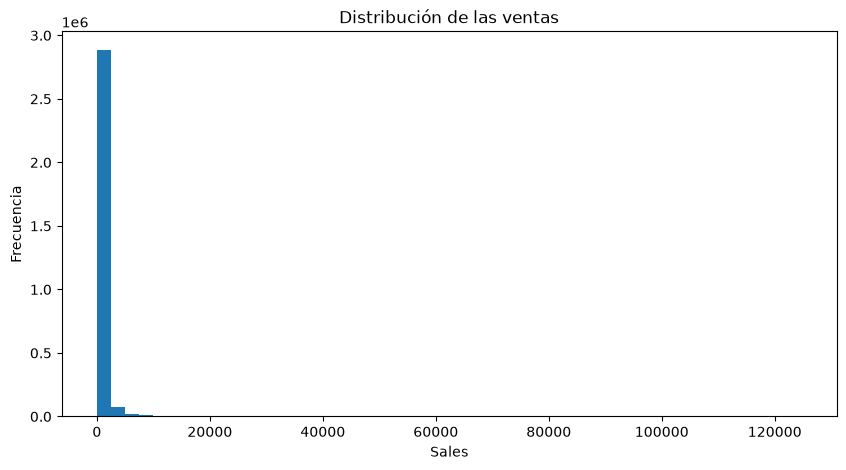

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["sales"], bins=50)
plt.title("Distribución de las ventas")
plt.xlabel("Sales")
plt.ylabel("Frecuencia")
plt.show()

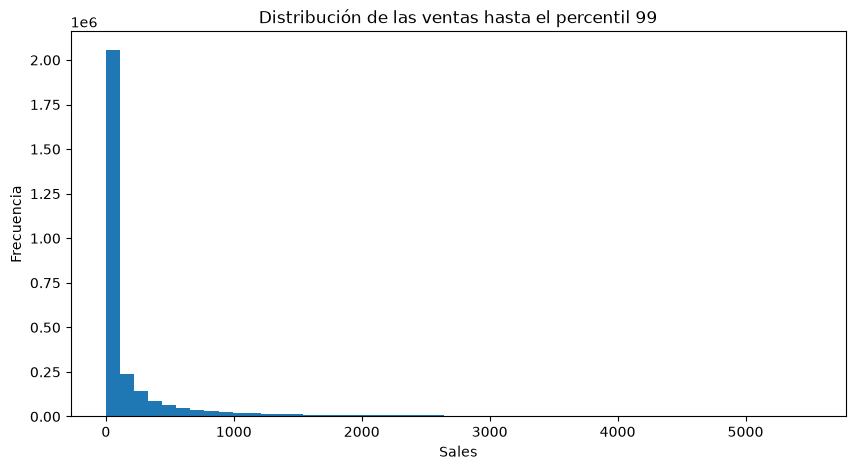

Percentil 99 de sales: 5507.0


In [17]:
sales_p99 = df["sales"].quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(
  df.loc[df["sales"] <= sales_p99, "sales"],
  bins=50
)
plt.title("Distribución de las ventas hasta el percentil 99")
plt.xlabel("Sales")
plt.ylabel("Frecuencia")
plt.show()

print("Percentil 99 de sales:", sales_p99)

### Distribución de las ventas

Las estadísticas descriptivas muestran una diferencia considerable entre la
mediana y el valor máximo de `sales`. Mientras que la mediana es de 11 unidades,
el valor máximo supera las 124,000, lo que indica que la distribución presenta
una fuerte asimetría hacia la derecha.

Por este motivo se presenta adicionalmente la distribución hasta el percentil
99. Esta visualización permite observar con mayor claridad el comportamiento
de la mayoría de los registros sin eliminar ni modificar todavía los valores
extremos del conjunto de datos.

In [18]:
sales_by_date = (
  df.groupby("date", as_index=False)["sales"].sum()
)

sales_by_date.head()

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


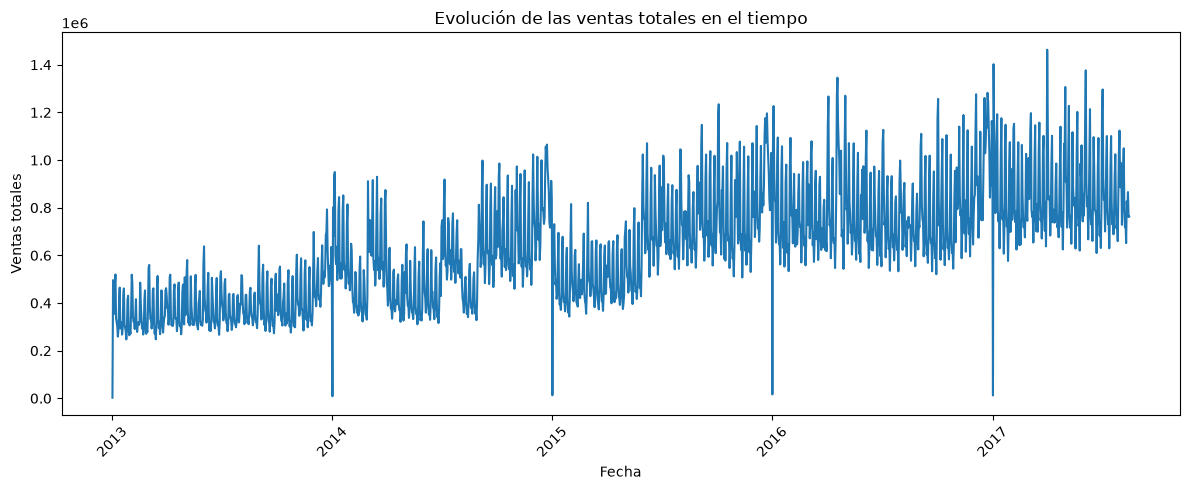

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(sales_by_date["date"], sales_by_date["sales"])
plt.title("Evolución de las ventas totales en el tiempo")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

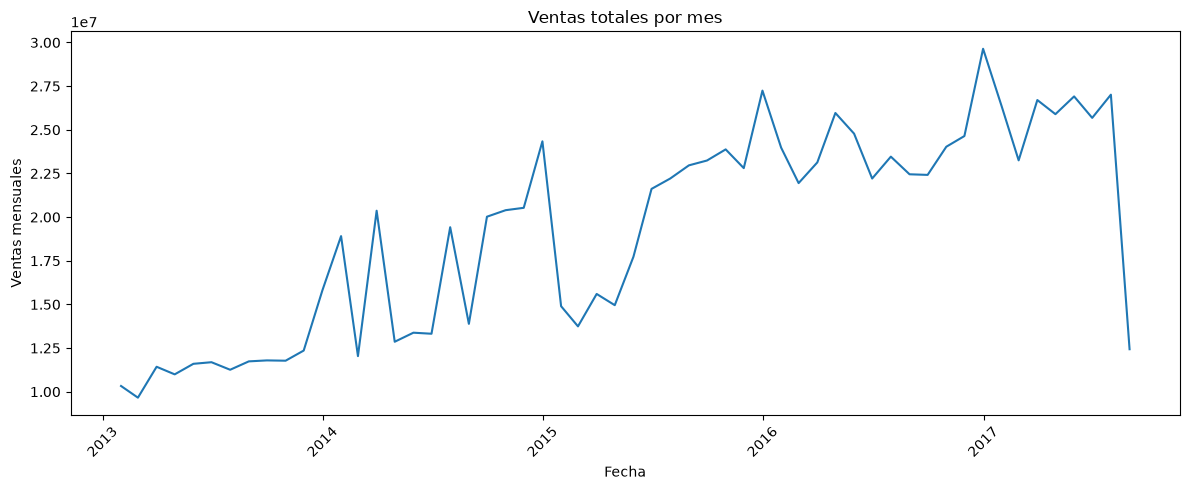

In [20]:
sales_monthly = (
  df.set_index("date")["sales"]
    .resample("ME")
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(sales_monthly["date"], sales_monthly["sales"])
plt.title("Ventas totales por mes")
plt.xlabel("Fecha")
plt.ylabel("Ventas mensuales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Evolución temporal de las ventas

La evolución diaria de las ventas muestra una tendencia general de crecimiento
a lo largo del periodo analizado. Los niveles de venta observados durante 2016
y 2017 son generalmente superiores a los registrados durante los primeros años
del conjunto de datos.

También se observan fluctuaciones recurrentes y algunos descensos pronunciados
en fechas específicas. Esto sugiere que las ventas presentan un comportamiento
dependiente del tiempo y que pueden existir patrones estacionales.

Al analizar los datos a nivel mensual, la tendencia de crecimiento se observa
con mayor claridad, ya que la agregación reduce parte de la variabilidad diaria.

Es importante señalar que el último punto de 2017 corresponde a un mes
incompleto, debido a que el dataset termina el 15 de agosto de 2017. Por lo
tanto, la caída observada en ese último mes no debe interpretarse como una
disminución real de las ventas.

In [22]:
promotion_summary = (
  df.assign(has_promotion=df["onpromotion"] > 0)
    .groupby("has_promotion")["sales"]
    .agg(["count", "mean", "median"])
)

promotion_summary

,count,mean,median
has_promotion,,,
False,2389559,158.246681,3.0
True,611329,1137.693730,373.0


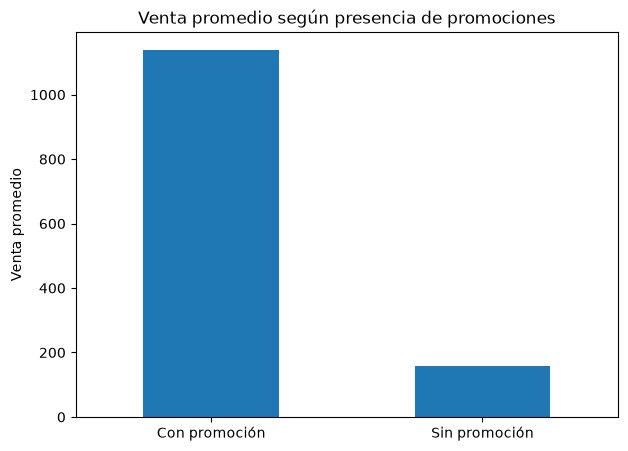

In [23]:
promotion_plot = (
  df.assign(
      promotion_status=df["onpromotion"].gt(0).map({
        False: "Sin promoción",
        True: "Con promoción"
      })
    )
    .groupby("promotion_status")["sales"]
    .mean()
)

plt.figure(figsize=(7, 5))
promotion_plot.plot(kind="bar")
plt.title("Venta promedio según presencia de promociones")
plt.xlabel("")
plt.ylabel("Venta promedio")
plt.xticks(rotation=0)
plt.show()

In [24]:
sales_by_type = (df.groupby("type")["sales"].mean().sort_values(ascending=False))

sales_by_type

type
A    705.878743
D    350.979407
B    326.739714
E    269.121301
C    197.263301
Name: sales, dtype: float64

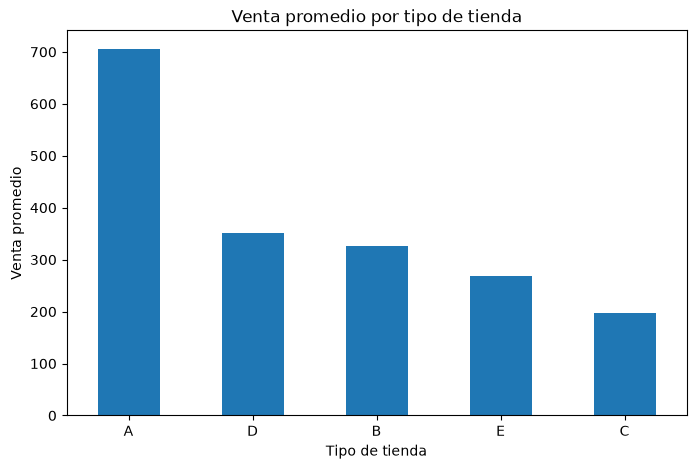

In [25]:
plt.figure(figsize=(8, 5))
sales_by_type.plot(kind="bar")
plt.title("Venta promedio por tipo de tienda")
plt.xlabel("Tipo de tienda")
plt.ylabel("Venta promedio")
plt.xticks(rotation=0)
plt.show()

In [26]:
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
  "Valores faltantes": missing_values,
  "Porcentaje (%)": missing_percentage
})

missing_summary

,Valores faltantes,Porcentaje (%)
id,0,0.00
date,0,0.00
store_nbr,0,0.00
family,0,0.00
sales,0,0.00
onpromotion,0,0.00
city,0,0.00
state,0,0.00
type,0,0.00
cluster,0,0.00


### Relación entre promociones y ventas

Los registros correspondientes a productos en promoción presentan ventas
considerablemente mayores que aquellos sin promoción. Las observaciones sin
promoción tienen una venta promedio aproximada de 158 unidades y una mediana
de 3, mientras que las observaciones con promoción presentan una venta promedio
cercana a 1,138 unidades y una mediana de 373.

Esta diferencia indica una asociación importante entre la presencia de
promociones y el nivel de ventas, por lo que `onpromotion` puede ser una
variable relevante para el posterior entrenamiento del modelo.

Sin embargo, este análisis muestra una asociación y no permite afirmar por sí
solo que las promociones sean la causa directa del incremento en las ventas.

### Ventas según el tipo de tienda

Las ventas promedio presentan diferencias importantes dependiendo del tipo de
tienda. Las tiendas de tipo A muestran la mayor venta promedio, con
aproximadamente 706 unidades, seguidas por los tipos D y B. Por otra parte,
las tiendas de tipo C presentan el promedio más bajo, cercano a 197 unidades.

Estas diferencias sugieren que el tipo de tienda contiene información
relacionada con el comportamiento de las ventas y podría ser una característica
útil para el modelo.

### Valores faltantes

La revisión de valores faltantes muestra que todas las variables se encuentran
completas excepto `dcoilwtico`. Esta variable contiene **928,422 valores
faltantes**, equivalentes aproximadamente al **30.94 %** de los registros.

Debido a que se trata de una proporción considerable, eliminar todos los
registros con valores faltantes provocaría una pérdida importante de
información. Por esta razón, durante la etapa de limpieza se analizará una
estrategia adecuada para tratar esta variable conservando la mayor cantidad
posible de observaciones.

## 3. Limpieza y preparación de los datos

En esta etapa se revisan los principales problemas de calidad del conjunto de
datos antes de entrenar el modelo. Se analizarán valores faltantes, registros
duplicados, posibles valores atípicos y tipos de datos incorrectos.

Cada decisión de limpieza será documentada con el objetivo de conservar la
mayor cantidad de información posible y evitar modificaciones innecesarias
sobre los datos.

In [27]:
duplicados = df.duplicated().sum()

print("Número de registros duplicados:", duplicados)
print("Porcentaje de duplicados:", round(duplicados / len(df) * 100, 4), "%")

Número de registros duplicados: 0
Porcentaje de duplicados: 0.0 %


In [28]:
duplicados_clave = df.duplicated(
  subset=["date", "store_nbr", "family"]
).sum()

print(
  "Duplicados por fecha, tienda y familia:",
  duplicados_clave
)

Duplicados por fecha, tienda y familia: 0


### Registros duplicados

No se identificaron registros completamente duplicados ni múltiples
observaciones para una misma combinación de fecha, tienda y familia de
productos. Por esta razón, no fue necesario eliminar registros en esta etapa.

In [29]:
df.dtypes

id                      int64
date           datetime64[us]
store_nbr               int64
family                    str
sales                 float64
onpromotion             int64
city                      str
state                     str
type                      str
cluster                 int64
dcoilwtico            float64
dtype: object

### Tipos de datos

La variable `date`, que originalmente se carga desde el archivo CSV como texto,
fue convertida al tipo `datetime` para permitir operaciones temporales y una
posterior división cronológica de los datos.

Las demás variables presentan tipos adecuados para su almacenamiento. Sin
embargo, algunas variables numéricas como `store_nbr` y `cluster` representan
identificadores o categorías y no cantidades continuas, por lo que esta
naturaleza será considerada posteriormente al preparar las variables para
el modelo.

Por lo tanto, no se identificaron otras conversiones de tipo necesarias en
esta etapa.

In [30]:
oil_clean = oil.copy()

# Ordenar cronológicamente
oil_clean = oil_clean.sort_values("date")

# Revisar valores faltantes originales
print(
  "Valores faltantes en oil antes:",
  oil_clean["dcoilwtico"].isna().sum()
)

Valores faltantes en oil antes: 43


In [31]:
full_dates = pd.DataFrame({
  "date": pd.date_range(
    start=train["date"].min(),
    end=train["date"].max(),
    freq="D"
  )
})

oil_daily = full_dates.merge(
  oil_clean,
  on="date",
  how="left"
)

print(
  "Valores faltantes antes del tratamiento:",
  oil_daily["dcoilwtico"].isna().sum()
)

Valores faltantes antes del tratamiento: 525


In [32]:
oil_daily["dcoilwtico"] = (
  oil_daily["dcoilwtico"]
  .interpolate(method="linear")
  .ffill()
  .bfill()
)

print(
  "Valores faltantes después del tratamiento:",
  oil_daily["dcoilwtico"].isna().sum()
)

Valores faltantes después del tratamiento: 0


In [33]:
df_clean = df.drop(columns=["dcoilwtico"]).merge(
  oil_daily,
  on="date",
  how="left"
)

print(
  "Valores faltantes en df_clean:",
  df_clean["dcoilwtico"].isna().sum()
)

print("Dimensiones:", df_clean.shape)

Valores faltantes en df_clean: 0
Dimensiones: (3000888, 11)


### Tratamiento de valores faltantes

La única variable con valores faltantes fue `dcoilwtico`, correspondiente al
precio diario del petróleo. Aproximadamente el 30.94 % de los registros no
contaba con un valor asociado.

Eliminar estas observaciones supondría perder una proporción considerable del
dataset. Además, debido a que el precio del petróleo corresponde a una serie
temporal, se decidió completar los valores faltantes mediante interpolación
lineal entre fechas consecutivas.

Para los posibles valores faltantes ubicados en los extremos de la serie se
utilizó propagación hacia adelante y hacia atrás (`ffill` y `bfill`). De esta
forma se conserva la totalidad de los registros sin utilizar información de
otras variables para estimar el precio del petróleo.

In [34]:
q1 = df_clean["sales"].quantile(0.25)
q3 = df_clean["sales"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers_sales = (
  (df_clean["sales"] < lower_bound) |
  (df_clean["sales"] > upper_bound)
)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Límite inferior:", lower_bound)
print("Límite superior:", upper_bound)
print("Posibles outliers:", outliers_sales.sum())
print(
  "Porcentaje:",
  round(outliers_sales.mean() * 100, 2),
  "%"
)

Q1: 0.0
Q3: 195.84725
IQR: 195.84725
Límite inferior: -293.770875
Límite superior: 489.61812499999996
Posibles outliers: 447105
Porcentaje: 14.9 %


### Valores atípicos

Mediante el método del rango intercuartílico (IQR) se identificaron **447,105
registros** como posibles valores atípicos en la variable `sales`, equivalentes
aproximadamente al **14.9 %** del conjunto de datos.

Sin embargo, estos valores no fueron eliminados automáticamente. En este
contexto, una venta considerablemente superior al resto puede representar un
comportamiento legítimo asociado con determinadas tiendas, familias de productos,
promociones o periodos de alta demanda.

Además, durante el análisis exploratorio se observó que `sales` presenta una
distribución fuertemente asimétrica hacia la derecha. Por esta razón, aplicar el
criterio IQR de manera estricta podría eliminar una cantidad importante de
observaciones válidas y modificar artificialmente el comportamiento real de las
ventas.

Por lo tanto, se decidió **conservar los valores atípicos** para el entrenamiento
del modelo baseline y considerar su impacto posteriormente durante la evaluación.

## 4. Entrenamiento del modelo baseline

El problema corresponde a una tarea de **regresión**, ya que la variable
objetivo `sales` es numérica y representa la cantidad de ventas registradas.

Como modelo baseline se utilizará una **regresión Ridge**. Este modelo permite
establecer un punto de partida sencillo antes de probar modelos más complejos.
Ridge es una extensión de la regresión lineal que incorpora regularización para
reducir el efecto de coeficientes excesivamente grandes.

Debido a que los datos presentan una estructura temporal, la división entre
entrenamiento y prueba se realizará de manera **cronológica**. Utilizar una
división aleatoria podría permitir que observaciones futuras aparecieran en el
conjunto de entrenamiento mientras se evalúan fechas anteriores.

Se utilizarán los primeros años para entrenamiento y los últimos 15 días del
dataset como conjunto de prueba.

In [36]:
df_model = df_clean.copy()

# Creación de variables temporales a partir de la fecha
df_model["year"] = df_model["date"].dt.year
df_model["month"] = df_model["date"].dt.month
df_model["day"] = df_model["date"].dt.day
df_model["day_of_week"] = df_model["date"].dt.dayofweek

df_model[
  ["date", "year", "month", "day", "day_of_week"]
].head()

,date,year,month,day,day_of_week
0,2013-01-01,2013,1,1,1
1,2013-01-01,2013,1,1,1
2,2013-01-01,2013,1,1,1
3,2013-01-01,2013,1,1,1
4,2013-01-01,2013,1,1,1


In [37]:
test_start_date = pd.Timestamp("2017-08-01")

train_data = df_model[df_model["date"] < test_start_date].copy()
test_data = df_model[df_model["date"] >= test_start_date].copy()

print("Periodo de entrenamiento:")
print(train_data["date"].min(), "a", train_data["date"].max())

print("\nPeriodo de prueba:")
print(test_data["date"].min(), "a", test_data["date"].max())

print("\nRegistros de entrenamiento:", len(train_data))
print("Registros de prueba:", len(test_data))

Periodo de entrenamiento:
2013-01-01 00:00:00 a 2017-07-31 00:00:00

Periodo de prueba:
2017-08-01 00:00:00 a 2017-08-15 00:00:00

Registros de entrenamiento: 2974158
Registros de prueba: 26730


### División de entrenamiento y prueba

La división de los datos se realizó respetando el orden temporal. Las
observaciones anteriores al 1 de agosto de 2017 se utilizaron para entrenamiento,
mientras que los registros correspondientes del 1 al 15 de agosto de 2017 se
reservaron para prueba.

Esta estrategia permite simular un escenario más cercano al uso real del
modelo: entrenarlo utilizando información histórica y posteriormente evaluar
su capacidad para estimar ventas de fechas futuras.

In [38]:
numeric_features = [
  "onpromotion",
  "dcoilwtico",
  "year",
  "month",
  "day",
  "day_of_week"
]

categorical_features = [
  "store_nbr",
  "family",
  "city",
  "state",
  "type",
  "cluster"
]

target = "sales"

In [39]:
X_train = train_data[numeric_features + categorical_features]
y_train = train_data[target]

X_test = test_data[numeric_features + categorical_features]
y_test = test_data[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2974158, 12)
y_train: (2974158,)

X_test: (26730, 12)
y_test: (26730,)


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

In [41]:
numeric_transformer = Pipeline(
  steps=[
    ("scaler", StandardScaler())
  ]
)

categorical_transformer = Pipeline(
  steps=[
    (
      "onehot",
      OneHotEncoder(
        handle_unknown="ignore"
      )
    )
  ]
)

preprocessor = ColumnTransformer(
  transformers=[
    (
      "num",
      numeric_transformer,
      numeric_features
    ),
    (
      "cat",
      categorical_transformer,
      categorical_features
    )
  ]
)

In [42]:
baseline_model = Pipeline(
  steps=[
    ("preprocessor", preprocessor),
    (
      "model",
      Ridge(
        alpha=1.0,
        solver="lsqr"
      )
    )
  ]
)

baseline_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

### Preparación de las variables

Para entrenar el modelo se excluyó la variable `id`, ya que funciona únicamente
como identificador del registro.

Las variables numéricas fueron estandarizadas mediante `StandardScaler`,
mientras que las variables categóricas fueron transformadas mediante
`OneHotEncoder`. Se utilizó `handle_unknown="ignore"` para permitir que el
modelo procese categorías que eventualmente no estuvieran presentes en el
conjunto de entrenamiento.

El preprocesamiento y el modelo fueron integrados en un `Pipeline` de
Scikit-learn. De esta manera, las transformaciones se ajustan utilizando
únicamente el conjunto de entrenamiento, reduciendo el riesgo de introducir
información del conjunto de prueba.

In [43]:
baseline_model.fit(X_train, y_train)

print("Modelo baseline entrenado correctamente.")

Modelo baseline entrenado correctamente.


In [44]:
print(
  "Modelo utilizado:",
  baseline_model.named_steps["model"]
)

Modelo utilizado: Ridge(solver='lsqr')


### Modelo baseline

Se entrenó correctamente un modelo de regresión Ridge utilizando exclusivamente
las observaciones correspondientes al periodo de entrenamiento.

El modelo se utiliza como **baseline**, por lo que no se realizó optimización de
hiperparámetros. Su propósito es proporcionar un punto de referencia inicial
sobre el desempeño que puede alcanzarse con un modelo relativamente sencillo
y con las características disponibles.

En etapas posteriores podrían incorporarse características específicas de
series de tiempo, como rezagos de ventas (`lags`), medias móviles o información
adicional sobre días festivos, así como modelos más especializados. Sin embargo,
estas mejoras quedan fuera del alcance del modelo base de esta actividad.

## 5. Evaluación del modelo baseline

Después de entrenar el modelo baseline, se evalúa su desempeño utilizando el
conjunto de prueba correspondiente a los últimos 15 días del dataset.

Debido a que se trata de un problema de regresión, se utilizarán las métricas
**MAE (Mean Absolute Error)** y **RMSE (Root Mean Squared Error)**.

- **MAE** indica, en promedio, qué tan alejadas se encuentran las predicciones
  de los valores reales y mantiene las mismas unidades que la variable `sales`.
- **RMSE** también mide el error de predicción, pero penaliza con mayor fuerza
  los errores grandes.

Adicionalmente se calculará el coeficiente **R²** como una medida complementaria
de la proporción de variabilidad de las ventas explicada por el modelo.

In [45]:
y_pred = baseline_model.predict(X_test)

print("Predicciones generadas:", len(y_pred))
print("Primeras 10 predicciones:")
print(y_pred[:10])

Predicciones generadas: 26730
Primeras 10 predicciones:
[ -36.54919138  -41.62956854  -40.46616554 2611.0898332   -41.65827856
  359.52835879  -34.6766962  1215.69524508  582.83971637  200.39950209]


In [46]:
negative_predictions = (y_pred < 0).sum()

print("Predicciones negativas:", negative_predictions)
print(
  "Porcentaje de predicciones negativas:",
  round(negative_predictions / len(y_pred) * 100, 2),
  "%"
)

Predicciones negativas: 6576
Porcentaje de predicciones negativas: 24.6 %


In [47]:
import numpy as np

from sklearn.metrics import (
  mean_absolute_error,
  mean_squared_error,
  r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

MAE:  300.15
RMSE: 699.96
R²:   0.6835


### Métricas utilizadas

El MAE se utiliza como una métrica principal debido a que ofrece una
interpretación directa del error promedio en las mismas unidades de `sales`.

El RMSE complementa este análisis al asignar mayor peso a errores grandes, lo
cual es relevante en este dataset debido a la presencia de ventas considerablemente
superiores al promedio.

El R² se incluye como una medida complementaria para conocer qué proporción de
la variabilidad observada en las ventas logra explicar el modelo baseline.

In [49]:
resultados = test_data[
  ["date", "store_nbr", "family", "sales"]
].copy()

resultados["predicted_sales"] = y_pred
resultados["absolute_error"] = np.abs(
  resultados["sales"] - resultados["predicted_sales"]
)

resultados.head(10)

,date,store_nbr,family,sales,predicted_sales,absolute_error
2974158,2017-08-01,1,AUTOMOTIVE,5.00000,-36.549191,41.549191
2974159,2017-08-01,1,BABY CARE,0.00000,-41.629569,41.629569
2974160,2017-08-01,1,BEAUTY,4.00000,-40.466166,44.466166
2974161,2017-08-01,1,BEVERAGES,2627.00000,2611.089833,15.910167
2974162,2017-08-01,1,BOOKS,0.00000,-41.658279,41.658279
2974163,2017-08-01,1,BREAD/BAKERY,373.70898,359.528359,14.180621
2974164,2017-08-01,1,CELEBRATION,11.00000,-34.676696,45.676696
2974165,2017-08-01,1,CLEANING,867.00000,1215.695245,348.695245
2974166,2017-08-01,1,DAIRY,668.00000,582.839716,85.160284
2974167,2017-08-01,1,DELI,133.58800,200.399502,66.811502


In [50]:
resultados["absolute_error"].describe()

count    26730.000000
mean       300.145000
std        632.358120
min          0.007406
25%         55.467120
50%        122.804131
75%        286.720009
max      11431.041978
Name: absolute_error, dtype: float64

In [51]:
resultados.sort_values(
  "absolute_error",
  ascending=False
).head(10)

,date,store_nbr,family,sales,predicted_sales,absolute_error
2982642,2017-08-05,47,BEVERAGES,14469.000,3037.958022,11431.041978
2984352,2017-08-06,44,PRODUCE,12913.622,2170.263539,10743.358461
2984367,2017-08-06,45,GROCERY I,15190.000,4947.538671,10242.461329
2984325,2017-08-06,44,BEVERAGES,12913.000,3294.464799,9618.535201
2984400,2017-08-06,46,GROCERY I,14233.000,4687.175474,9545.824526
2984466,2017-08-06,48,GROCERY I,14062.000,4529.846518,9532.153482
2984358,2017-08-06,45,BEVERAGES,12609.000,3156.166072,9452.833928
2982585,2017-08-05,45,GROCERY I,14189.000,4945.473360,9243.526640
2984424,2017-08-06,47,BEVERAGES,12295.000,3074.452226,9220.547774
2982543,2017-08-05,44,BEVERAGES,12455.000,3275.185042,9179.814958


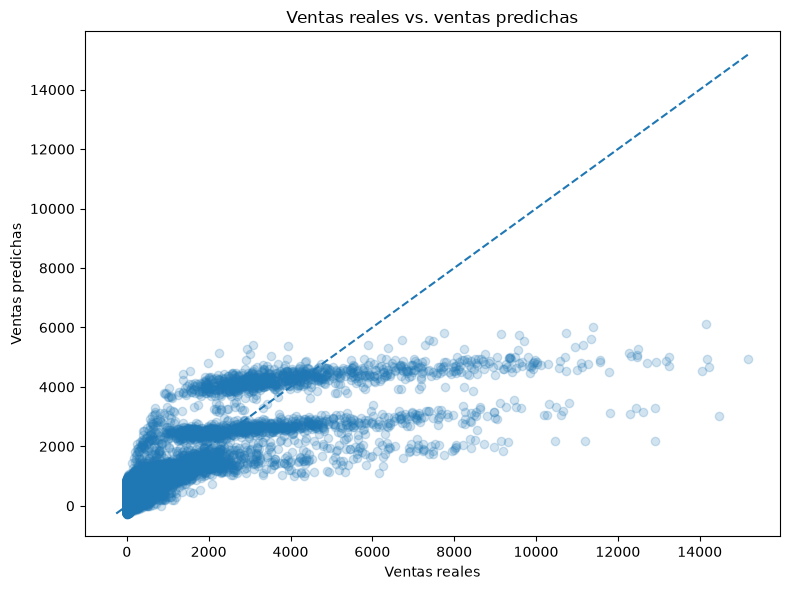

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
  y_test,
  y_pred,
  alpha=0.2
)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
  [min_value, max_value],
  [min_value, max_value],
  linestyle="--"
)

plt.title("Ventas reales vs. ventas predichas")
plt.xlabel("Ventas reales")
plt.ylabel("Ventas predichas")
plt.tight_layout()
plt.show()

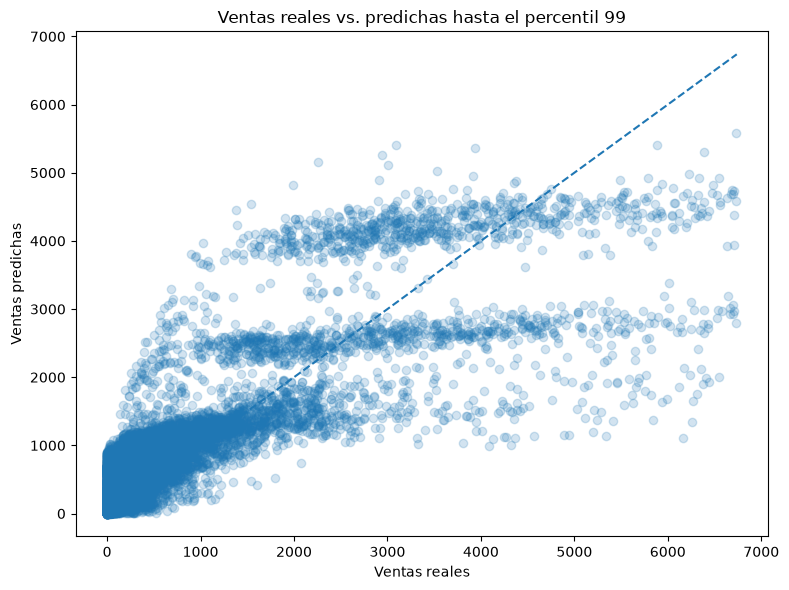

In [53]:
real_p99 = y_test.quantile(0.99)

mask = (
  (y_test <= real_p99) &
  (y_pred <= real_p99) &
  (y_pred >= 0)
)

plt.figure(figsize=(8, 6))

plt.scatter(
  y_test[mask],
  y_pred[mask],
  alpha=0.2
)

plt.plot(
  [0, real_p99],
  [0, real_p99],
  linestyle="--"
)

plt.title("Ventas reales vs. predichas hasta el percentil 99")
plt.xlabel("Ventas reales")
plt.ylabel("Ventas predichas")
plt.tight_layout()
plt.show()

In [54]:
daily_results = (
  resultados
  .groupby("date", as_index=False)
  .agg(
    actual_sales=("sales", "sum"),
    predicted_sales=("predicted_sales", "sum")
  )
)

daily_results

,date,actual_sales,predicted_sales
0,2017-08-01,9.885278e+05,8.356588e+05
1,2017-08-02,9.647120e+05,9.788465e+05
2,2017-08-03,7.280685e+05,8.649835e+05
3,2017-08-04,8.277757e+05,1.007239e+06
4,2017-08-05,9.656937e+05,9.467611e+05
5,2017-08-06,1.049559e+06,9.962836e+05
6,2017-08-07,7.974650e+05,7.483985e+05
7,2017-08-08,7.177663e+05,8.250064e+05
8,2017-08-09,7.341397e+05,9.525810e+05
9,2017-08-10,6.513869e+05,8.476226e+05


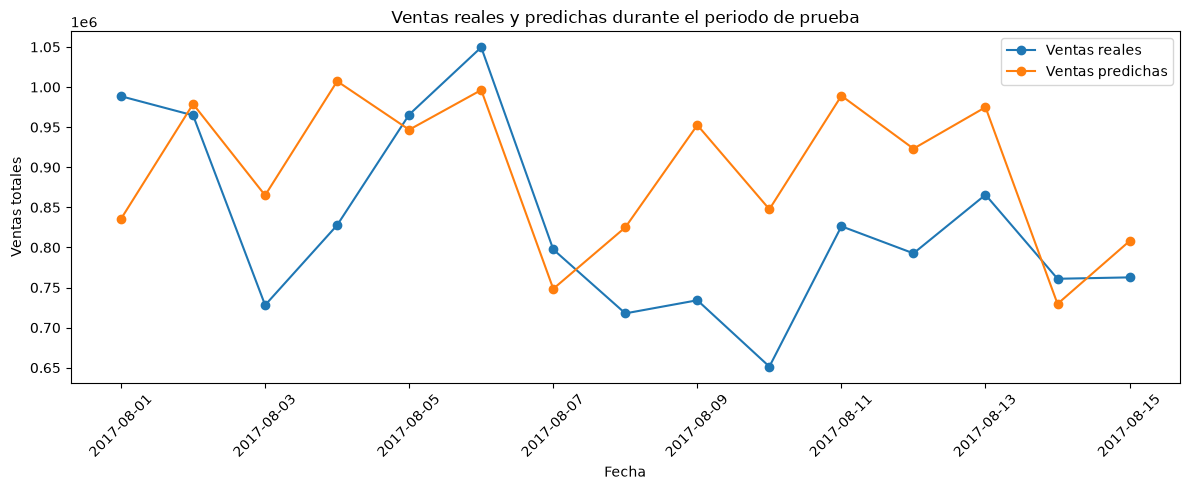

In [55]:
plt.figure(figsize=(12, 5))

plt.plot(
  daily_results["date"],
  daily_results["actual_sales"],
  marker="o",
  label="Ventas reales"
)

plt.plot(
  daily_results["date"],
  daily_results["predicted_sales"],
  marker="o",
  label="Ventas predichas"
)

plt.title("Ventas reales y predichas durante el periodo de prueba")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

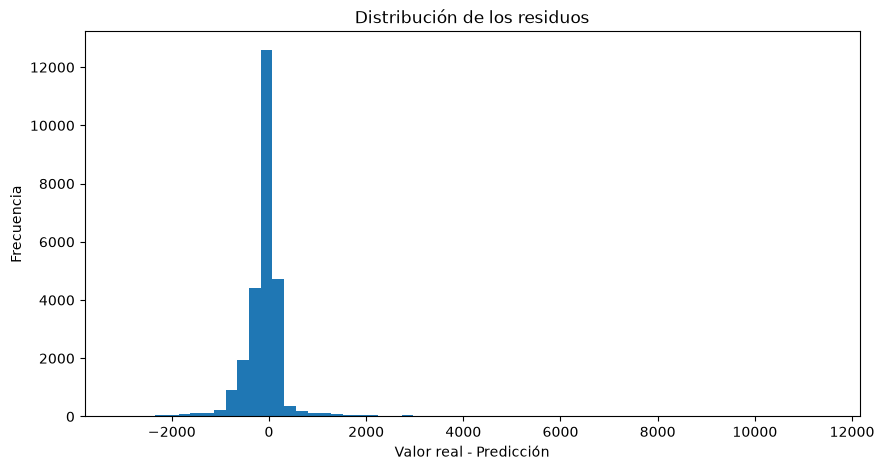

In [56]:
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(10, 5))
plt.hist(residuals, bins=60)
plt.title("Distribución de los residuos")
plt.xlabel("Valor real - Predicción")
plt.ylabel("Frecuencia")
plt.show()

In [57]:
print("Media de los residuos:", residuals.mean())
print("Mediana de los residuos:", np.median(residuals))

Media de los residuos: -37.215413583972584
Mediana de los residuos: -46.20476481208961


### Interpretación de la evaluación

El modelo Ridge utilizado como baseline obtuvo un **MAE de 300.15** y un
**RMSE de 699.96**. Esto indica que el error absoluto promedio de las
predicciones es de aproximadamente 300 unidades de venta. El hecho de que el
RMSE sea considerablemente mayor que el MAE muestra que existen algunas
predicciones con errores de gran magnitud, lo cual es consistente con la
presencia de valores elevados de ventas identificada durante el análisis
exploratorio.

El modelo obtuvo un **R² de 0.6835**, por lo que logra explicar aproximadamente
el 68.35 % de la variabilidad observada en las ventas del periodo de prueba.
Este resultado representa un punto de referencia razonable para un modelo
baseline que no incorpora características avanzadas de series de tiempo.

También se identificaron **6,576 predicciones negativas**, equivalentes al
24.6 % del conjunto de prueba. Debido a que una cantidad de ventas no puede ser
negativa, este comportamiento representa una limitación importante de la
regresión Ridge para este problema.

Los mayores errores se concentran principalmente en observaciones con ventas
muy elevadas, especialmente en familias como `BEVERAGES`, `GROCERY I` y
`PRODUCE`. Esto muestra que el modelo tiene dificultades para representar
algunos picos de demanda.

Finalmente, la media de los residuos fue de aproximadamente -37.22. Dado que
el residuo se calculó como valor real menos predicción, este valor negativo
indica una ligera tendencia general del modelo a sobreestimar las ventas. Sin
embargo, existen también observaciones de ventas muy altas que el modelo
subestima considerablemente.

En conclusión, el modelo proporciona un baseline útil, pero podría mejorarse
incorporando variables específicas de series de tiempo, como rezagos de ventas,
medias móviles y patrones históricos recientes, o mediante modelos capaces de
representar relaciones no lineales.

## 6. Registro del experimento con MLflow

Para mantener evidencia reproducible del modelo baseline, se utiliza MLflow
Tracking para registrar los principales parámetros del modelo, las métricas
obtenidas durante la evaluación y un artefacto gráfico con la comparación entre
ventas reales y predichas.

In [59]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("store_sales_baseline")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento configurado correctamente.")

2026/10/04 23:11:50 INFO mlflow.tracking.fluent: Experiment with name 'store_sales_baseline' does not exist. Creating a new experiment.


Tracking URI: http://127.0.0.1:5000
Experimento configurado correctamente.


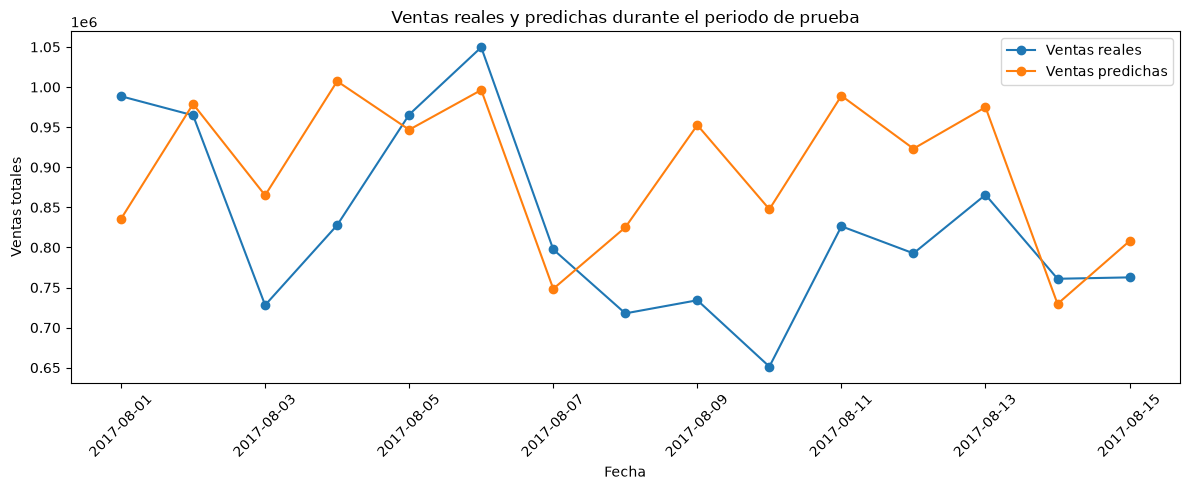

In [60]:
plt.figure(figsize=(12, 5))

plt.plot(
  daily_results["date"],
  daily_results["actual_sales"],
  marker="o",
  label="Ventas reales"
)

plt.plot(
  daily_results["date"],
  daily_results["predicted_sales"],
  marker="o",
  label="Ventas predichas"
)

plt.title("Ventas reales y predichas durante el periodo de prueba")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
  "baseline_evaluation.png",
  dpi=150,
  bbox_inches="tight"
)

plt.show()

In [61]:
with mlflow.start_run(run_name="ridge_baseline") as run:

  # Parámetros del modelo
  mlflow.log_param("model", "Ridge")
  mlflow.log_param("alpha", 1.0)
  mlflow.log_param("solver", "lsqr")
  # Configuración del experimento
  mlflow.log_param("target", "sales")
  mlflow.log_param("test_start_date", "2017-08-01")
  mlflow.log_param("train_rows", len(X_train))
  mlflow.log_param("test_rows", len(X_test))
  # Métricas
  mlflow.log_metric("mae", mae)
  mlflow.log_metric("rmse", rmse)
  mlflow.log_metric("r2", r2)
  mlflow.log_metric(
    "negative_predictions_percentage",
    negative_predictions / len(y_pred) * 100
  )
  # Artefacto
  mlflow.log_artifact("baseline_evaluation.png")
  run_id = run.info.run_id

print("Experimento registrado correctamente.")
print("Run ID:", run_id)

🏃 View run ridge_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/1fb652c551754da49080e7598f99f42d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Experimento registrado correctamente.
Run ID: 1fb652c551754da49080e7598f99f42d


In [62]:
import joblib

joblib.dump(
  baseline_model,
  "ridge_baseline_model.joblib"
)

with mlflow.start_run(run_id=run_id):
  mlflow.log_artifact(
    "ridge_baseline_model.joblib",
    artifact_path="model"
  )

print("Modelo registrado como artefacto.")

🏃 View run ridge_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/1fb652c551754da49080e7598f99f42d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Modelo registrado como artefacto.


### Evidencia del experimento registrado en MLflow

La siguiente captura muestra el experimento `store_sales_baseline` y el run
`ridge_baseline` registrados en MLflow Tracking. Se observan los parámetros
utilizados para entrenar el modelo y las métricas obtenidas durante su
evaluación.

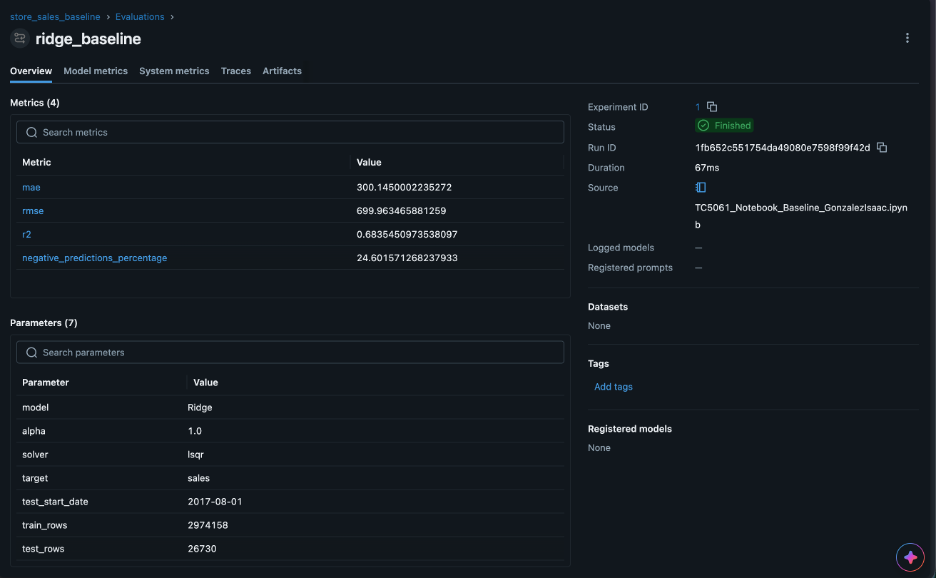

In [63]:
from IPython.display import Image, display

display(Image(filename="mlflow_evidence.png"))

## 7. Reflexión final

El desarrollo de este ejercicio permitió recorrer el flujo completo de un
proyecto de Machine Learning, desde la exploración y limpieza de los datos
hasta el entrenamiento, evaluación y registro de un modelo baseline. Aunque el
modelo Ridge obtuvo un R² de 0.6835, los resultados también muestran varias
oportunidades de mejora. Una de las principales sería incorporar características
propias de series de tiempo, como ventas de días anteriores, medias móviles y
patrones históricos, ya que el modelo actual utiliza principalmente información
general de la fecha, tienda y producto. También sería conveniente comparar
diferentes modelos y mantener un proceso de validación temporal para evitar
utilizar información futura durante el entrenamiento.

Desde la perspectiva de MLOps, mejoraría este flujo automatizando la preparación
de los datos, el entrenamiento y la evaluación, además de utilizar control de
versiones para datos, código y modelos. MLflow resulta especialmente útil porque
permite registrar los parámetros, métricas y artefactos de cada experimento,
facilitando la comparación y reproducibilidad de los resultados.

En mi área profesional de desarrollo de software, estos aprendizajes se
relacionan directamente con la importancia de construir procesos reproducibles,
automatizados y trazables. Un modelo de Machine Learning no debería considerarse
únicamente como un algoritmo que produce predicciones, sino como parte de un
sistema de software que necesita control de cambios, pruebas, monitoreo y
mantenimiento. Aplicar prácticas de MLOps permite integrar el trabajo de Machine
Learning con prácticas de ingeniería de software y facilita llevar los modelos
desde la experimentación hasta entornos productivos de una forma más confiable.